# 03 — Vented Box: Driver, Vent, and Radiated Sum

This notebook exercises the vented (bass-reflex) enclosure model.

**Notation.** Subscripts: $d$ driver, $v$ vent, $b$ box, $a$ acoustic, $m$ mechanical.

The box air is a compliance $C_{ab}$ and the vent air is an inertance $M_{av}$. The box impedance includes leakage $R_{al}$ in parallel, and the vent branch carries the box spring in series with its own mass and radiation resistance:

$$Z_{ab} = \left(j\omega C_{ab} + \frac{1}{R_{al}}\right)^{-1}, \qquad Z_{av} = R_{rv} + j\omega M_{av} + Z_{ab}$$

Seen from the driver, the box and the vent are in parallel. The acoustic load of the enclosure is

$$Z_a = Z_{ab} - \frac{Z_{ab}^2}{Z_{av}}$$

**Sign convention:** cone velocity $U_d$ and vent velocity $U_v$ are both positive **outward**, and the time dependence is $e^{j\omega t}$. The vent flow follows from the rear pressure:

$$Q_v = -\frac{Z_{ab}}{Z_{av}}\,Q_d, \qquad p = p_d + p_v$$

Both sources radiate into a half-space ($2\pi$ monopole), consistent with the baffled-piston vent radiation resistance and the flanged end correction $8a_v/3\pi$.

The notebook covers:

1. Tuning and vent geometry
2. Vented vs. sealed vs. free air (impedance, excursion, SPL)
3. Driver and vent contributions, including their relative phase
4. Effect of leakage losses ($Q_L$) and tuning
5. Validation against the full 3×3 coupled system

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")

from src.constants import AIR
from src.components.driver import Driver
from src.components.enclosure import SealedBox, VentedBox
from src.components.radiation import MonopoleRadiation
from src.system import LoudspeakerSystem
from src.utils import magnitude_to_db

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## Setup

The driver is the same one used in notebook 01. The vent is defined by **radius and length**; the helper below solves the length for a target tuning frequency, only to make exploring tuning convenient.

The drive level is 1 V, as in notebook 01.

In [2]:
driver = Driver.from_thiele_small(
    Re=3.4,
    Le=1.43e-3,
    Fs=35.7,
    Qms=6.620,
    Qes=0.360,
    Vas=12.10e-3,
    Sd=124.7e-4,
    Xmax=6e-3,
    Pe=100,
)

freqs = np.logspace(1, 3, 1200)
voltage = 10.0
distance = 1.0

Vb = 14.2e-3            # m^3, net internal volume
vent_radius = 0.029    # m
target_fb = 36.0      # Hz
Ql = 7.0              # leakage Q at fb


def vent_length_for_tuning(fb, volume, vent_radius, medium=AIR):
    # Uses the default end corrections of VentedBox (flanged outer, no inner).
    area = np.pi * vent_radius**2
    effective = medium.speed_of_sound**2 * area / ((2 * np.pi * fb)**2 * volume)
    return effective - 8 * vent_radius / (3 * np.pi)


vent_length = vent_length_for_tuning(target_fb, Vb, vent_radius)
assert vent_length > 0, "Target tuning needs a negative vent length; increase Vb or reduce the vent area."

vented_box = VentedBox(
    volume=Vb,
    vent_radius=vent_radius,
    vent_length=vent_length,
    Ql=Ql,
)

free_air = LoudspeakerSystem(driver, radiation=MonopoleRadiation())
sealed = LoudspeakerSystem(driver, SealedBox(Vb), radiation=MonopoleRadiation())
vented = LoudspeakerSystem(driver, vented_box, radiation=MonopoleRadiation())

fb = vented_box.vent_tuning_frequency()

print(f"Vb:                    {1e3 * Vb:.1f} L")
print(f"Vas / Vb:              {driver.Vas() / Vb:.3f}")
print(f"Vent radius:           {1e2 * vent_radius:.1f} cm")
print(f"Vent length:           {1e2 * vent_length:.1f} cm")
print(f"Effective length:      {1e2 * vented_box.effective_length:.1f} cm")
print(f"Vent area:             {1e4 * vented_box.vent_area:.1f} cm²")
print(f"Vent acoustic mass Mav: {vented_box.vent_acoustic_mass():.2f} kg/m⁴")
print(f"Tuning frequency fb:   {fb:.2f} Hz")
print(f"Sealed fc / Qtc:       {sealed.resonance_frequency:.2f} Hz / {sealed.total_q:.3f}")

Vb:                    14.2 L
Vas / Vb:              0.852
Vent radius:           2.9 cm
Vent length:           40.5 cm
Effective length:      43.0 cm
Vent area:             26.4 cm²
Vent acoustic mass Mav: 195.25 kg/m⁴
Tuning frequency fb:   36.00 Hz
Sealed fc / Qtc:       48.58 Hz / 0.465


In [3]:
fa_response = free_air.solve(freqs, voltage=voltage, distance=distance)
sealed_response = sealed.solve(freqs, voltage=voltage, distance=distance)
vented_response = vented.solve(freqs, voltage=voltage, distance=distance)

# System block diagram

The enclosure acts on the driver through $S_d^2 Z_a$, which enters the cone's mechanical admittance. The vent volume flow $Q_v = S_v U_v$ is a parallel branch tapped from the cone volume velocity $Q_d = S_d U_d$, through the gain $-Z_{ab}/Z_{av}$. The driver and vent pressures, $p_d$ and $p_v$, are added as complex quantities at the output junction.

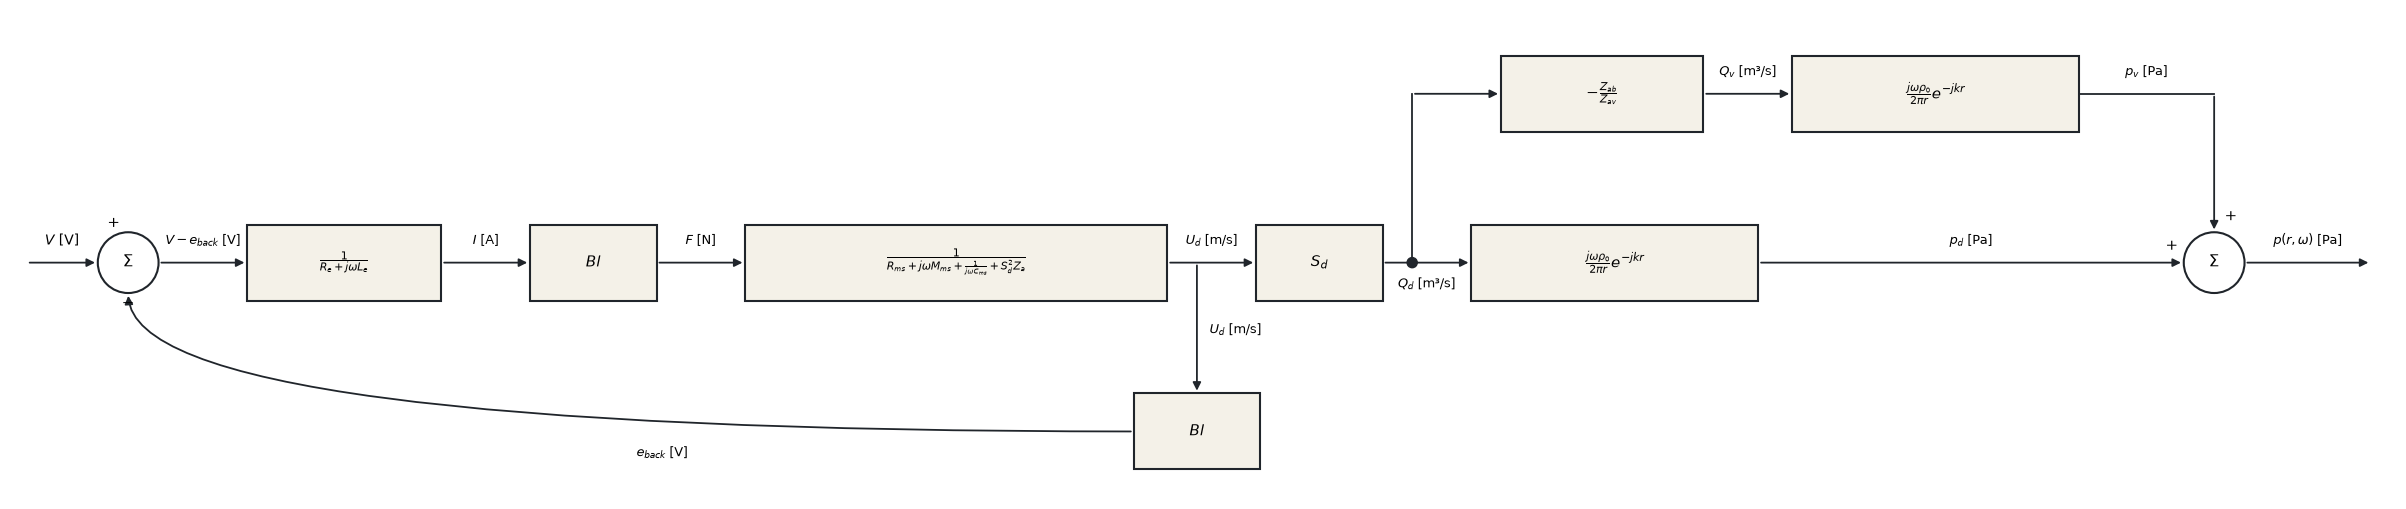

In [4]:
from src.diagrams.rendering import render_block_diagram

figure, _ = render_block_diagram(
    vented.block_diagram(output="pressure", distance=distance)
)

# Experiment 1 — Electrical impedance

The vented box should show **two impedance peaks** with a minimum near $f_b$, instead of the single peak of the sealed box.

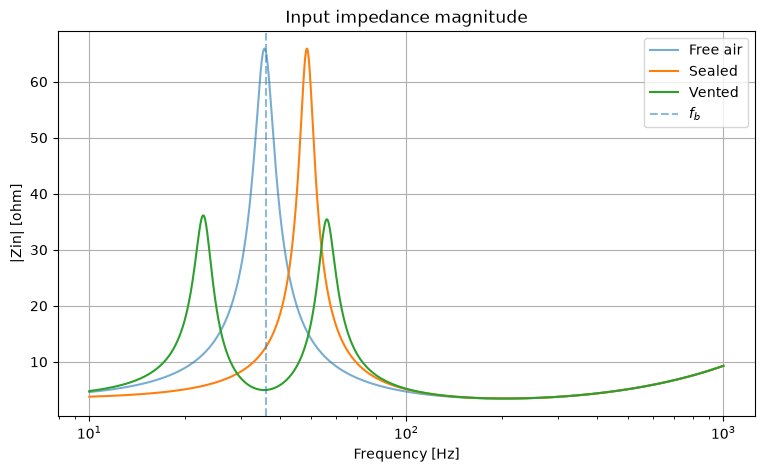

In [5]:
plt.figure()
plt.semilogx(freqs, np.abs(fa_response.input_impedance), label="Free air", alpha=0.6)
plt.semilogx(freqs, np.abs(sealed_response.input_impedance), label="Sealed")
plt.semilogx(freqs, np.abs(vented_response.input_impedance), label="Vented")
plt.axvline(fb, linestyle="--", alpha=0.5, label="$f_b$")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|Zin| [ohm]")
plt.title("Input impedance magnitude")
plt.legend()
plt.show()

# Experiment 2 — Cone excursion

Near $f_b$ the cone excursion should have a pronounced **minimum**. Below $f_b$ the vent unloads the cone and excursion rises rapidly, which is why vented systems usually need a high-pass filter.

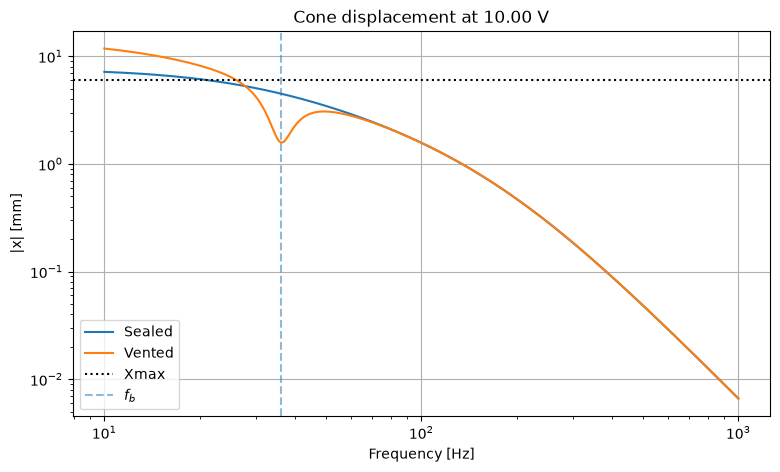

In [6]:
plt.figure()
plt.loglog(freqs, 1e3 * np.abs(sealed_response.displacement), label="Sealed")
plt.loglog(freqs, 1e3 * np.abs(vented_response.displacement), label="Vented")
plt.axhline(1e3 * driver.Xmax, color="k", linestyle=":", label="Xmax")
plt.axvline(fb, linestyle="--", alpha=0.5, label="$f_b$")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|x| [mm]")
plt.title(f"Cone displacement at {voltage:.2f} V")
plt.legend()
plt.show()

# Experiment 3 — Driver and vent flow

At $f_b$ the vent volume velocity should peak while the driver's drops. The vent air speed is the quantity to watch for port noise (chuffing).

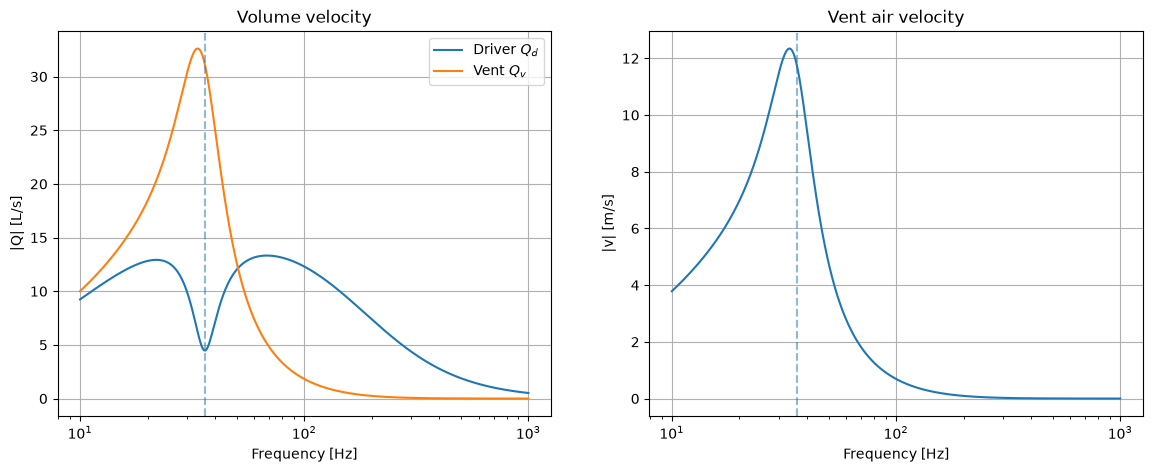

Peak vent air velocity: 12.34 m/s at 33.5 Hz


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogx(freqs, 1e3 * np.abs(vented_response.volume_velocity), label="Driver $Q_d$")
axes[0].semilogx(freqs, 1e3 * np.abs(vented_response.vent_volume_velocity), label="Vent $Q_v$")
axes[0].axvline(fb, linestyle="--", alpha=0.5)
axes[0].set_xlabel("Frequency [Hz]")
axes[0].set_ylabel("|Q| [L/s]")
axes[0].set_title("Volume velocity")
axes[0].legend()

axes[1].semilogx(freqs, np.abs(vented_response.vent_velocity))
axes[1].axvline(fb, linestyle="--", alpha=0.5)
axes[1].set_xlabel("Frequency [Hz]")
axes[1].set_ylabel("|v| [m/s]")
axes[1].set_title("Vent air velocity")

plt.show()

idx = np.argmax(np.abs(vented_response.vent_velocity))
print(f"Peak vent air velocity: {np.abs(vented_response.vent_velocity[idx]):.2f} m/s at {freqs[idx]:.1f} Hz")

# Experiment 4 — Radiated SPL

The driver and vent pressures are added as **complex** quantities. The plot shows each contribution on its own and the total.

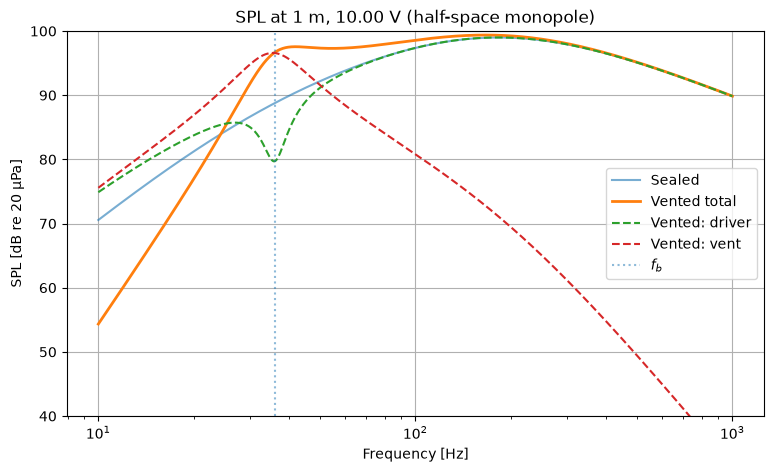

In [8]:
p_ref = 20e-6

plt.figure()
plt.semilogx(freqs, magnitude_to_db(sealed_response.pressure, p_ref), label="Sealed", alpha=0.6)
plt.semilogx(freqs, magnitude_to_db(vented_response.pressure, p_ref), label="Vented total", linewidth=2)
plt.semilogx(freqs, magnitude_to_db(vented_response.driver_pressure, p_ref), "--", label="Vented: driver")
plt.semilogx(freqs, magnitude_to_db(vented_response.vent_pressure, p_ref), "--", label="Vented: vent")
plt.axvline(fb, linestyle=":", alpha=0.5, label="$f_b$")
plt.ylim(40, 100)
plt.xlabel("Frequency [Hz]")
plt.ylabel("SPL [dB re 20 µPa]")
plt.title(f"SPL at {distance:.0f} m, {voltage:.2f} V (half-space monopole)")
plt.legend()
plt.show()

## Driver/vent phase

Well above $f_b$ the two sources should be in phase, and the relative phase should pass through roughly 90° at $f_b$. Below $f_b$ they approach opposition, which produces the steep roll-off.

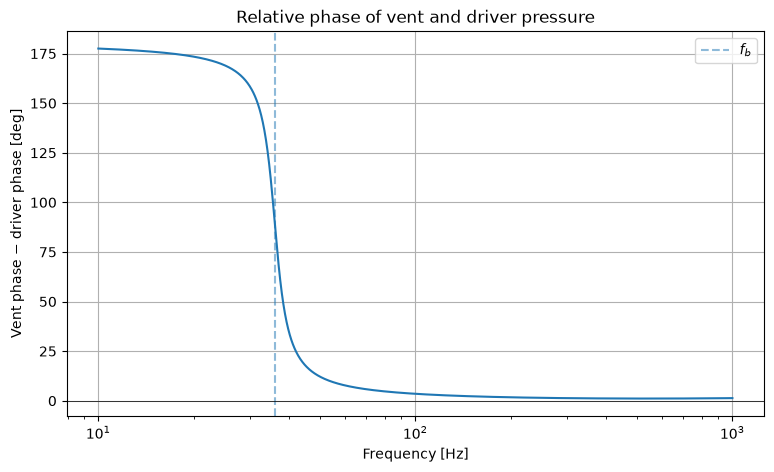

In [9]:
relative_phase = np.degrees(
    np.angle(vented_response.vent_pressure / vented_response.driver_pressure)
)

plt.figure()
plt.semilogx(freqs, relative_phase)
plt.axvline(fb, linestyle="--", alpha=0.5, label="$f_b$")
plt.axhline(0, color="k", linewidth=0.5)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Vent phase − driver phase [deg]")
plt.title("Relative phase of vent and driver pressure")
plt.legend()
plt.show()

# Experiment 5 — Parameter studies

## Leakage loss $Q_L$

Lower $Q_L$ means more leakage. It damps the impedance and vent-velocity peaks near $f_b$. `Ql=None` is lossless.

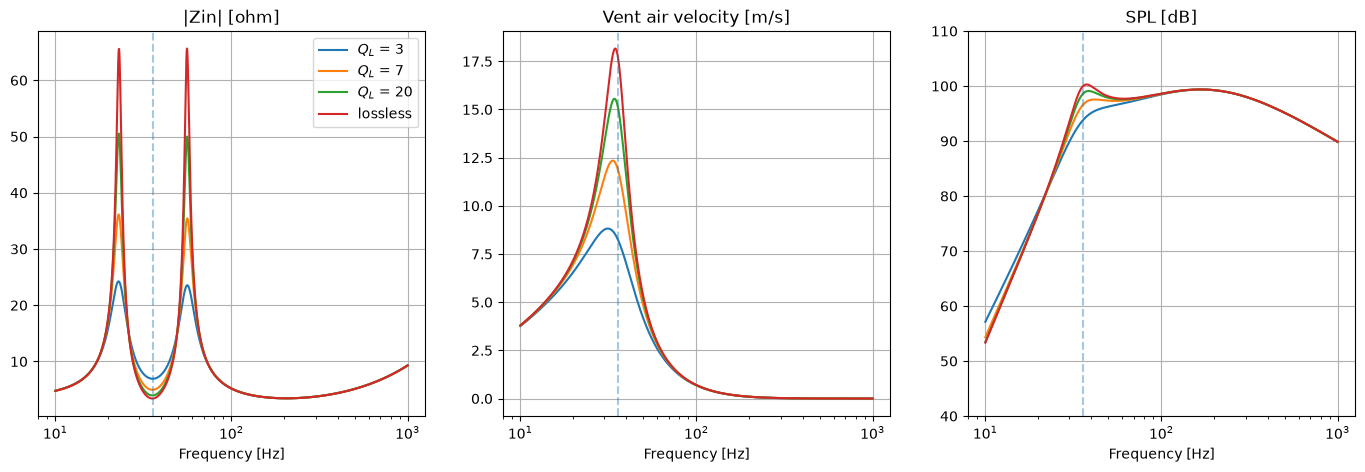

In [10]:
ql_values = [3, 7, 20, None]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ql in ql_values:
    box = VentedBox(Vb, vent_radius, vent_length, Ql=ql)
    response = LoudspeakerSystem(driver, box, radiation=MonopoleRadiation()).solve(
        freqs, voltage=voltage, distance=distance
    )
    label = "lossless" if ql is None else f"$Q_L$ = {ql}"

    axes[0].semilogx(freqs, np.abs(response.input_impedance), label=label)
    axes[1].semilogx(freqs, np.abs(response.vent_velocity), label=label)
    axes[2].semilogx(freqs, magnitude_to_db(response.pressure, p_ref), label=label)

axes[0].set_title("|Zin| [ohm]")
axes[1].set_title("Vent air velocity [m/s]")
axes[2].set_title("SPL [dB]")
axes[2].set_ylim(40, 110)

for ax in axes:
    ax.axvline(fb, linestyle="--", alpha=0.4)
    ax.set_xlabel("Frequency [Hz]")

axes[0].legend()
plt.show()

## Tuning frequency

Same box and vent radius, with the vent length solved for each target $f_b$.

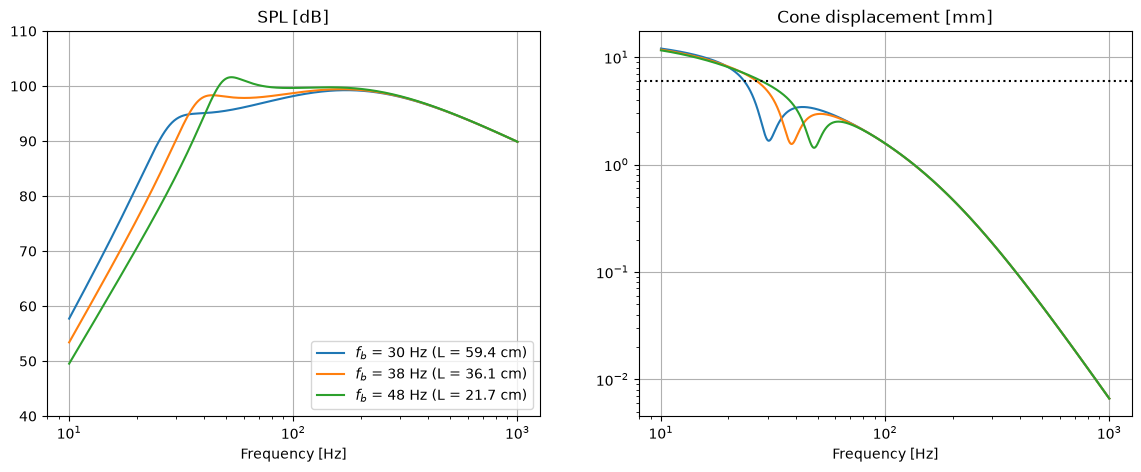

In [11]:
fb_values = [30, 38, 48]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for fb_target in fb_values:
    length = vent_length_for_tuning(fb_target, Vb, vent_radius)
    box = VentedBox(Vb, vent_radius, length, Ql=Ql)
    response = LoudspeakerSystem(driver, box, radiation=MonopoleRadiation()).solve(
        freqs, voltage=voltage, distance=distance
    )
    label = f"$f_b$ = {fb_target} Hz (L = {1e2 * length:.1f} cm)"

    axes[0].semilogx(freqs, magnitude_to_db(response.pressure, p_ref), label=label)
    axes[1].loglog(freqs, 1e3 * np.abs(response.displacement), label=label)

axes[0].set_ylim(40, 110)
axes[0].set_title("SPL [dB]")
axes[1].set_title("Cone displacement [mm]")
axes[1].axhline(1e3 * driver.Xmax, color="k", linestyle=":")

for ax in axes:
    ax.set_xlabel("Frequency [Hz]")

axes[0].legend()
plt.show()

# Validation

## Reduced one-port model vs. the full 3×3 system

The model solves the driver with the vent eliminated. Here the coupled system, written with $U_d$ and $U_v$ both positive outward,

$$\begin{bmatrix} Z_e & Bl & 0 \\ -Bl & Z_{md} & -j\mu/\omega \\ 0 & -j\mu/\omega & Z_{mv} \end{bmatrix}\begin{bmatrix} I \\ U_d \\ U_v \end{bmatrix} = \begin{bmatrix} V \\ 0 \\ 0 \end{bmatrix}$$

is solved explicitly at each frequency (lossless box: `Ql=None`, `Qp=None`). The box compression is $\Delta V = -S_d x_d - S_v x_v$, so the coupling terms carry the opposite sign to a formulation with the cone positive inward. Here $Z_{mv} = S_v^2 Z_{av}$ uses $M_v' = \rho_0 S_v L_{eff}$ (end correction included).

In [12]:
def coupled_reference(driver, box, freqs, voltage, medium=AIR):
    rho0, c = medium.density, medium.speed_of_sound
    Sd, Sv, V0 = driver.Sd, box.vent_area, box.volume

    Kbd = rho0 * c**2 * Sd**2 / V0
    Kbv = rho0 * c**2 * Sv**2 / V0
    mu = rho0 * c**2 * Sd * Sv / V0
    Mv_eff = rho0 * Sv * box.effective_length    # Mv' in the formulation

    out = {"I": [], "Ud": [], "Uv": []}
    for f in freqs:
        omega = 2 * np.pi * f
        Ze = driver.Re + 1j * omega * driver.Le
        Zmd = driver.Rms + 1j * (omega * driver.Mms - (1 / driver.Cms + Kbd) / omega)
        Rrv = rho0 * Sv**2 * omega**2 / (2 * np.pi * c)
        Zmv = Rrv + 1j * (omega * Mv_eff - Kbv / omega)

        A = np.array([
            [Ze, driver.Bl, 0],
            [-driver.Bl, Zmd, -1j * mu / omega],
            [0, -1j * mu / omega, Zmv],
        ])
        I, Ud, Uv = np.linalg.solve(A, [voltage, 0, 0])
        out["I"].append(I)
        out["Ud"].append(Ud)
        out["Uv"].append(Uv)

    return {k: np.array(v) for k, v in out.items()}


lossless_box = VentedBox(Vb, vent_radius, vent_length, Ql=None, Qp=None)
lossless = LoudspeakerSystem(driver, lossless_box, radiation=MonopoleRadiation())
lossless_response = lossless.solve(freqs, voltage=voltage, distance=distance)
ref = coupled_reference(driver, lossless_box, freqs, voltage)

Qv_ref = lossless_box.vent_area * ref["Uv"]

err_Ud = np.max(np.abs(lossless_response.velocity - ref["Ud"]) / np.abs(ref["Ud"]))
err_Qv = np.max(np.abs(lossless_response.vent_volume_velocity - Qv_ref) / np.abs(Qv_ref))
err_Zin = np.max(np.abs(lossless_response.input_impedance - voltage / ref["I"]) / np.abs(voltage / ref["I"]))

print(f"Max relative error, Ud:     {err_Ud:.2e}")
print(f"Max relative error, Qv:     {err_Qv:.2e}")
print(f"Max relative error, Zin:    {err_Zin:.2e}")

Max relative error, Ud:     2.54e-14
Max relative error, Qv:     1.19e-15
Max relative error, Zin:    6.26e-15
